In [ ]:
from google.colab import files
uploaded = files.upload()

Saving daily_max_temperature_C.xlsx to daily_max_temperature_C.xlsx


In [ ]:
import pandas as pd

df = pd.read_excel("daily_max_temperature_C.xlsx")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df.set_index('Date', inplace=True)


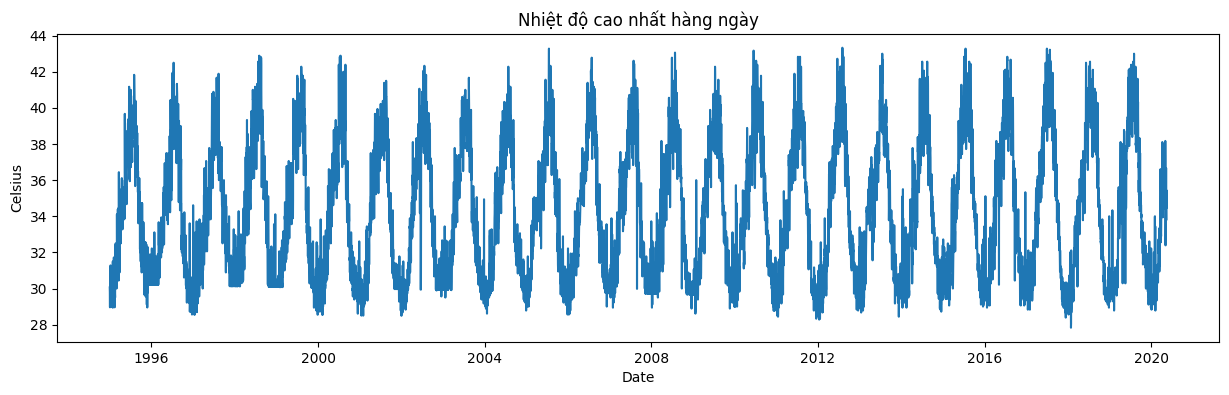

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))
plt.plot(df['Daily_Global_City_Max_Temp_C'])
plt.title("Nhiệt độ cao nhất hàng ngày")
plt.xlabel("Date")
plt.ylabel("Celsius")
plt.show()


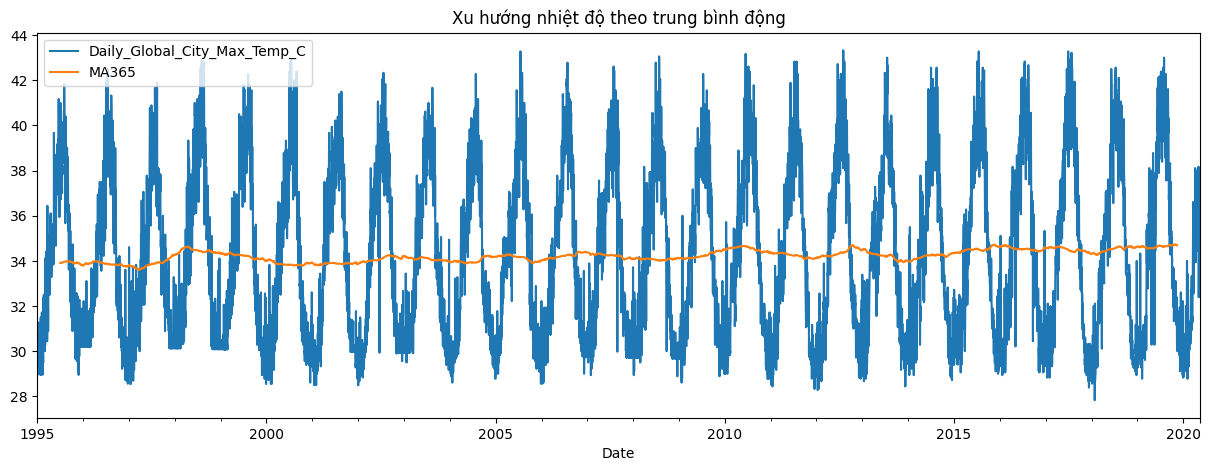

In [ ]:
df['MA365'] = df['Daily_Global_City_Max_Temp_C'].rolling(365, center=True).mean()

df[['Daily_Global_City_Max_Temp_C', 'MA365']].plot(figsize=(15,5))
plt.title("Xu hướng nhiệt độ theo trung bình động")
plt.show()


In [ ]:
import pandas as pd

# Giả định: df là DataFrame của bạn, và index là kiểu datetime
# Cột MA365 đã được tính với center=True
years_to_check = [1995, 2000, 2010, 2019]
ma_results = []

for year in years_to_check:
    # 1. Lọc dữ liệu trong phạm vi năm hiện tại
    # Lọc các dòng có năm trong index bằng năm đang xét
    data_in_year = df[df.index.year == year]

    # 2. Loại bỏ các giá trị NaN trong cột 'MA365' của năm đó
    valid_ma_data = data_in_year.dropna(subset=['MA365'])

    if valid_ma_data.empty:
        # Xử lý nếu không có giá trị MA365 hợp lệ nào trong năm này
        ma_results.append({
            'Năm': year,
            'Ngày trích xuất': 'Không xác định',
            'MA365 (°C)': 'Không xác định (NaN)'
        })
        continue

    # 3. Trích xuất giá trị tại dòng cuối cùng có MA365 hợp lệ
    # Đối với 1995, 2000, 2010: Đây sẽ là ngày 31-12
    # Đối với 2019: Đây sẽ là ngày ~12-11 (ngày cuối cùng trước khi dữ liệu bị NaN)
    final_day_data = valid_ma_data.iloc[-1]

    ma_results.append({
        'Năm': year,
        'Ngày trích xuất': final_day_data.name.strftime('%Y-%m-%d'),
        'MA365 (°C)': final_day_data['MA365']
    })

# Chuyển kết quả thành DataFrame và hiển thị
results_df = pd.DataFrame(ma_results)

print("### 🌡️ Kết Quả Trung Bình Trượt 365 Ngày (Sử dụng center=True)")
print(results_df.to_markdown(index=False, floatfmt=".4f"))

### 🌡️ Kết Quả Trung Bình Trượt 365 Ngày (Sử dụng center=True)
|   Năm | Ngày trích xuất   |   MA365 (°C) |
|------:|:------------------|-------------:|
|  1995 | 1995-12-31        |      33.7991 |
|  2000 | 2000-12-31        |      33.9081 |
|  2010 | 2010-12-31        |      34.3811 |
|  2019 | 2019-11-13        |      34.6901 |


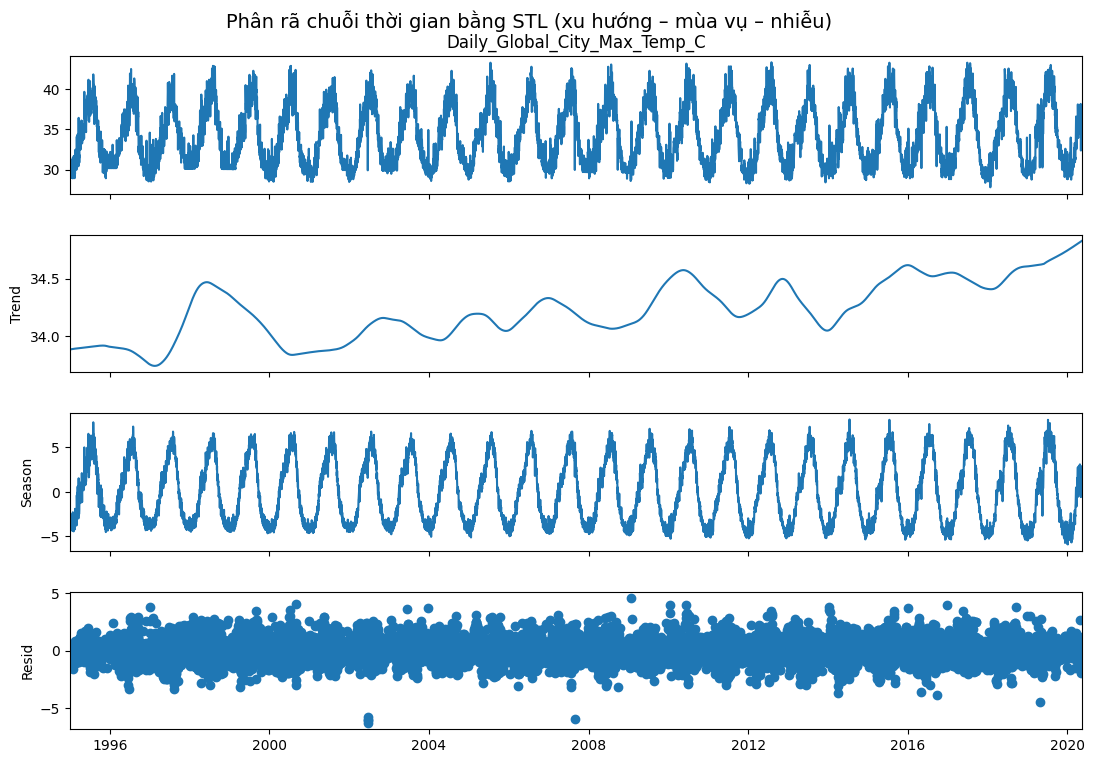

In [ ]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

stl = STL(df['Daily_Global_City_Max_Temp_C'], period=365)
result = stl.fit()

fig = result.plot()
fig.set_size_inches(12, 8)

plt.suptitle("Phân rã chuỗi thời gian bằng STL (xu hướng – mùa vụ – nhiễu)", fontsize=14)
plt.show()



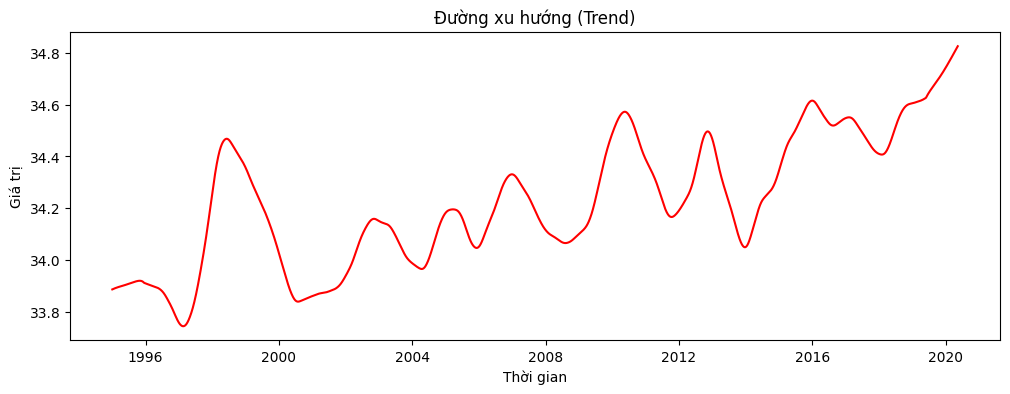

In [ ]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

stl = STL(df['Daily_Global_City_Max_Temp_C'], period=365)
result = stl.fit()

# Chỉ vẽ thành phần xu hướng
plt.figure(figsize=(12, 4))
plt.plot(result.trend, color='red')
plt.title("Đường xu hướng (Trend)")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.show()

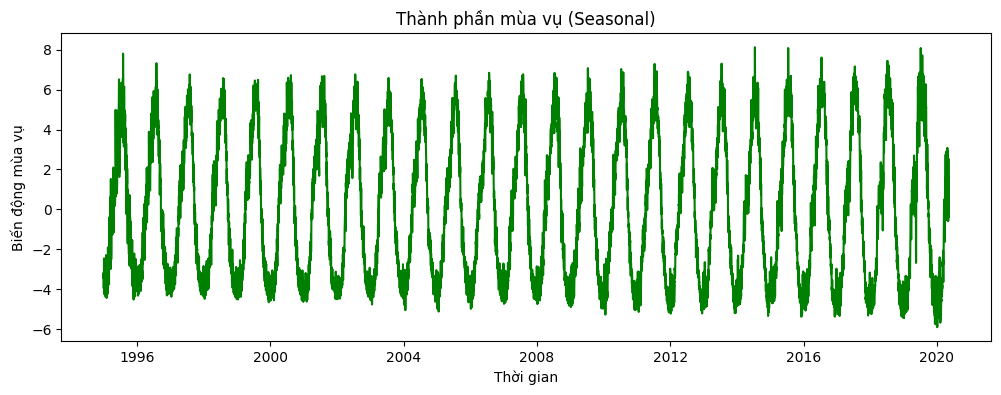

In [ ]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

stl = STL(df['Daily_Global_City_Max_Temp_C'], period=365)
result = stl.fit()

plt.figure(figsize=(12, 4))
plt.plot(result.seasonal, color='green')
plt.title("Thành phần mùa vụ (Seasonal)")
plt.xlabel("Thời gian")
plt.ylabel("Biến động mùa vụ")
plt.show()


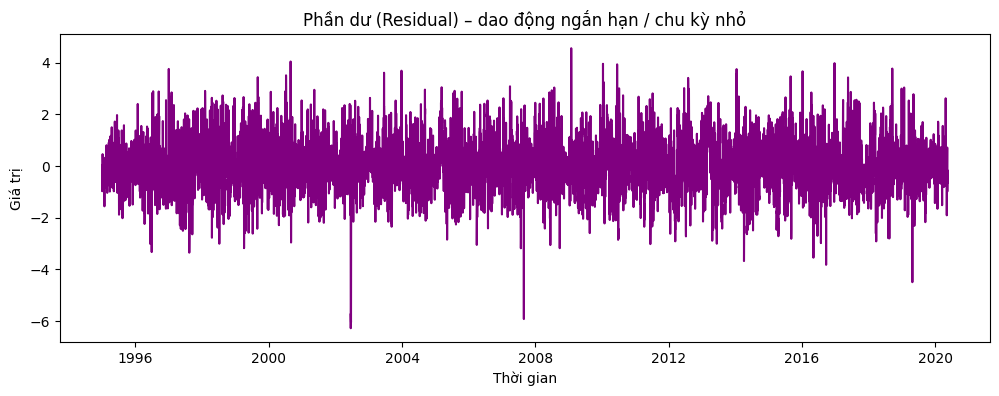

In [ ]:
plt.figure(figsize=(12,4))
plt.plot(result.resid, color='purple')
plt.title("Phần dư (Residual) – dao động ngắn hạn / chu kỳ nhỏ")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.show()


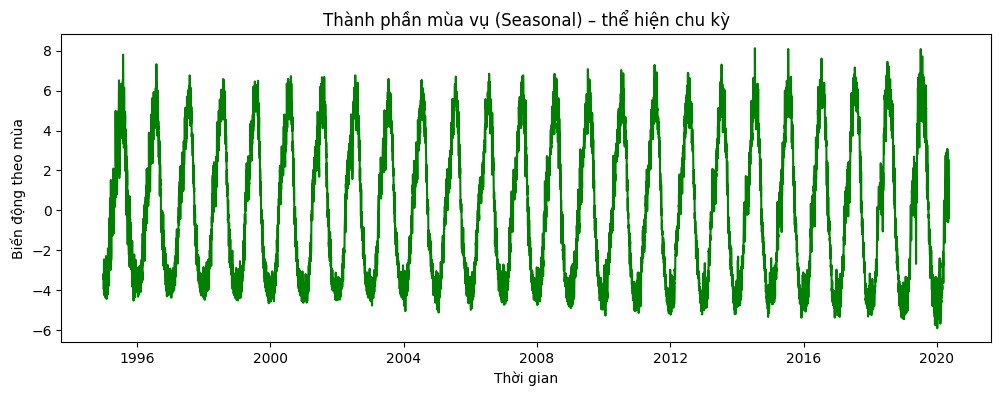

In [ ]:
plt.figure(figsize=(12,4))
plt.plot(result.seasonal, color='green')
plt.title("Thành phần mùa vụ (Seasonal) – thể hiện chu kỳ")
plt.xlabel("Thời gian")
plt.ylabel("Biến động theo mùa")
plt.show()


NameError: name 'data' is not defined

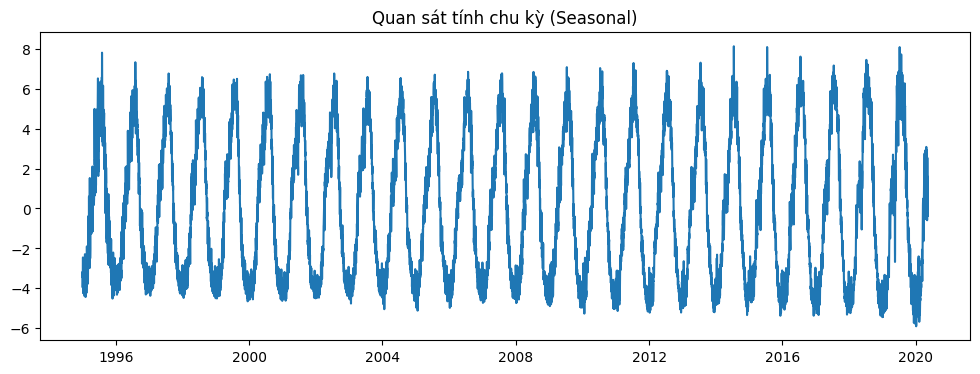

In [ ]:
plt.figure(figsize=(12,4))
plt.plot(result.seasonal)
plt.title("Quan sát tính chu kỳ (Seasonal)")
plt.show()
